# Contribuciones de Euler, concentración y muestreo por importancia

**Pregunta:** ¿Qué grupo de la cartera de 1.120 nombres es dueño de su capital, cuánto se aparta eso de su participación en la exposición, y puede el muestreo por importancia alcanzar la cola del 99,9% con una fracción de los escenarios?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- decir por qué las contribuciones de Euler de los grupos de una cartera suman su total, y comprobarlo en una simulación: exactamente para el déficit esperado, dentro de una tolerancia para el VaR;
- ver que las contribuciones al VaR son más ruidosas que las del déficit esperado, repitiendo la simulación con distintas semillas;
- comparar las contribuciones de una cartera finita con las asintóticas de forma cerrada, y leer qué dice la diferencia sobre la concentración;
- calcular el índice de Herfindahl y el número efectivo de nombres de una cartera;
- construir un estimador por muestreo por importancia para la cola con el giro exponencial, comprobar que es insesgado, y leer su razón de varianza frente al Monte Carlo simple.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Nombres de las luces de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El archivo comercial e industrial del caso C10, `data/derived/C10/commercial-industrial.json` (propietario: este repositorio; las tasas de pérdida detrás de su ajuste vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`). Contiene la **cartera ilustrativa** (`outputs.portfolio`: 20 nombres grandes, 100 medianos y 1.000 pequeños, 100 millones de USD, construida para el caso y nunca la de un banco), las contribuciones de Euler versionadas por grupo (`outputs.euler`) y la escalera versionada (`outputs.rungs`, con el peldaño de muestreo por importancia y sus diagnósticos). La celda siguiente lo carga e imprime los grupos de la cartera.

In [2]:
# Cargar el artefacto e imprimir los grupos de la cartera ilustrativa
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
groups = book["groups"]
pd_hat = out["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = out["fit"]["maximum_likelihood"]["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}

for g in groups:
    print(f"{g['id']:9s} {g['n_names']:5d} nombres x {g['ead_each']:>11,.0f} | PD {g['pd']:.5f}")

g-large      20 nombres x   2,000,000 | PD 0.00506
g-mid       100 nombres x     400,000 | PD 0.01012
g-small    1000 nombres x      20,000 | PD 0.01517


## Método

### Paso 1: las contribuciones de Euler y por qué suman

Un banco quiere saber de cuánto del capital de la cartera es responsable cada grupo. Para una medida de riesgo $\rho$ positivamente homogénea (escalar todas las exposiciones por $c$ escala el riesgo por $c$), el **principio de Euler** da la contribución del grupo $g$ como la derivada del riesgo respecto de su tamaño, y las contribuciones suman el total (Tasche, 2008, https://arxiv.org/abs/0708.2542). Para las dos medidas del caso son esperanzas condicionales de la pérdida del grupo $L_g$ dado el total $L$:

$$\mathrm{RC}_g^{\mathrm{VaR}}=E\big[L_g\mid L=\mathrm{VaR}_q(L)\big],\qquad \mathrm{RC}_g^{\mathrm{ES}}=E\big[L_g\mid L\ge \mathrm{VaR}_q(L)\big]$$

En una simulación la contribución al ES es un promedio sobre los escenarios de cola, con los pesos de Acerbi y Tasche del notebook 03, así que las contribuciones suman exactamente el ES muestral. La contribución al VaR condiciona en un nivel de pérdida, que casi ningún escenario alcanza, así que es ruidosa; el motor la suaviza con el estimador de núcleo de Tasche (2009, https://doi.org/10.1080/14697680802620599), un promedio de Nadaraya-Watson con núcleo gaussiano en el VaR muestral y el ancho de banda de Silverman $1{,}06\,\mathrm{sd}(L)\,S^{-1/5}$ (el ancho de banda es una elección del motor; el artículo no nombra ninguno). La estimación de núcleo tiene sesgo en el borde, así que su suma coincide con el VaR dentro de una tolerancia declarada, no exactamente. `euler_additivity` del motor prueba esa suma: verde cuando la brecha relativa está dentro de la tolerancia, roja sobre ella, sin ámbar. La celda siguiente simula la cartera conservando las pérdidas de cada grupo, calcula ambas contribuciones al 99% y al 99,9%, y prueba sus sumas, con las tolerancias que usa el flujo de datos: $10^{-6}$ para el ES y 0,01 para el VaR.

In [3]:
# Simular la cartera conservando las pérdidas de cada grupo, calcular ambas contribuciones y probar que suman
from riskvalidation.portfolio import copula, euler
from riskvalidation.portfolio import portfolio as pf
from riskvalidation.validation.portfolio import euler_additivity

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
sim = rungs["c2-gaussian-1f"]["simulation"]
sample = copula.simulate_gaussian(one, 100_000, sim["seed"], sim["chunk_size"], track_groups=True)
measures = pf.measures_from_sample(sample.losses, (0.99, 0.999), el)
tolerance = {"var": 0.01, "es": 1e-6}
print("escenarios:", sample.n_scenarios, "| pérdidas por grupo:", sample.group_losses.shape)

contributions = {}
for m in measures:
    rc_es = euler.es_contributions(sample.group_losses, sample.losses, m.level)
    rc_var = euler.var_contributions_kernel(sample.group_losses, sample.losses, m.level)
    contributions[m.level] = (rc_var, rc_es)
    test_es = euler_additivity(rc_es, m.es, tolerance["es"], model_id="gaussian-1f", segment=f"es-{m.level}")
    test_var = euler_additivity(rc_var, m.var, tolerance["var"], model_id="gaussian-1f", segment=f"var-{m.level}")
    print(f"q = {m.level}: ES {m.es:,.0f} | suma de contribuciones: {rc_es.sum():,.0f}")
    print(f"        brecha: {test_es.metric:.1e} | {LIGHTS[test_es.light.value]}")
    print(f"        VaR {m.var:,.0f} | suma de contribuciones: {rc_var.sum():,.0f}")
    print(f"        brecha: {test_var.metric:.1e} | {LIGHTS[test_var.light.value]}")

escenarios: 100000 | pérdidas por grupo: (100000, 3)
q = 0.99: ES 2,535,057 | suma de contribuciones: 2,535,057
        brecha: 1.3e-15 | verde
        VaR 2,088,000 | suma de contribuciones: 2,087,480
        brecha: 2.5e-04 | verde
q = 0.999: ES 3,609,180 | suma de contribuciones: 3,609,180
        brecha: 1.3e-16 | verde
        VaR 3,087,000 | suma de contribuciones: 3,082,159
        brecha: 1.6e-03 | verde


Las contribuciones por grupo, como parte del total, dicen a quién pertenece el capital. La celda siguiente calcula esas tres participaciones al 99,9% para cada grupo y las dibuja como barras.

exposición     0.400   0.400   0.200
VaR            0.591   0.269   0.139
ES             0.576   0.275   0.149


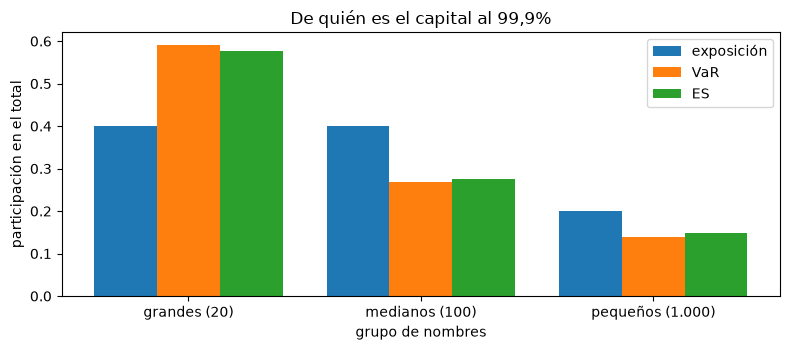

In [4]:
# Calcular las participaciones de exposición, VaR y ES de cada grupo al 99,9% y dibujarlas
rc_var_999, rc_es_999 = contributions[0.999]
exposure = np.array([g["n_names"] * g["ead_each"] for g in groups])
shares = {
    "exposición": exposure / exposure.sum(),
    "VaR": rc_var_999 / rc_var_999.sum(),
    "ES": rc_es_999 / rc_es_999.sum(),
}
group_labels = ["grandes (20)", "medianos (100)", "pequeños (1.000)"]
for name, values in shares.items():
    print(f"{name:12s}", " ".join(f"{v:7.3f}" for v in values))

fig, ax = plt.subplots(figsize=(8, 3.6))
position = np.arange(len(groups))
for k, (name, values) in enumerate(shares.items()):
    ax.bar(position + 0.27 * (k - 1), values, width=0.27, label=name)
ax.set_xticks(position, group_labels)
ax.set_xlabel("grupo de nombres")
ax.set_ylabel("participación en el total")
ax.set_title("De quién es el capital al 99,9%")
ax.legend()
fig.tight_layout()
plt.show()

La primera barra de cada grupo es su participación en la exposición, las otras su participación en el riesgo. Los 20 nombres grandes son el 40% de la exposición y llevan casi el 60% de ambas medidas de capital, mientras los 1.000 nombres pequeños son el 20% de la exposición y llevan cerca del 14%. Las participaciones de VaR y de ES cuentan la misma historia en el mismo orden, lo que tranquiliza porque salen de estimadores distintos. La figura muestra dónde se concentra la cartera; no muestra cuán confiable es cada participación, pues sale de una sola muestra de 100.000 escenarios. El paso siguiente repite la simulación para medir ese ruido.

### Paso 2: el ruido de las contribuciones al VaR

¿Cuánto se mueven las contribuciones de una simulación a la siguiente? La celda siguiente repite la simulación seis veces con 50.000 escenarios y una semilla distinta cada vez, y calcula la participación de cada grupo en el total al 99,9% de tres maneras: la contribución al ES; la contribución al VaR por núcleo; y una estimación simple de la definición, la pérdida media del grupo sobre los escenarios cuyo total está a menos de 2% del VaR (una comprobación de la definición, escrita en la propia celda, no un método del motor). Imprime la participación media de las seis corridas y el coeficiente de variación, la desviación estándar sobre la media.

In [5]:
# Repetir la simulación con seis semillas y comparar tres estimaciones de las participaciones
runs = {"ES": [], "VaR (núcleo)": [], "VaR (banda simple)": []}
for seed in range(900, 906):
    run = copula.simulate_gaussian(one, 50_000, seed, sim["chunk_size"], track_groups=True)
    m = pf.measures_from_sample(run.losses, (0.999,), el)[0]
    in_band = np.abs(run.losses - m.var) <= 0.02 * m.var
    estimates = (
        euler.es_contributions(run.group_losses, run.losses, 0.999),
        euler.var_contributions_kernel(run.group_losses, run.losses, 0.999),
        run.group_losses[in_band].mean(axis=0),
    )
    for key, values in zip(runs, estimates):
        runs[key].append(values / values.sum())

print(f"{'':22s} " + " ".join(f"{label:>18s}" for label in group_labels))
for key, repeated in runs.items():
    arr = np.array(repeated)
    cv = arr.std(axis=0, ddof=1) / arr.mean(axis=0)
    cells = [f"{arr.mean(axis=0)[k]:7.3f} (cv {cv[k]:.3f})" for k in range(len(groups))]
    print(f"{key:22s} " + " ".join(cells))

                             grandes (20)     medianos (100)   pequeños (1.000)
ES                       0.539 (cv 0.041)   0.304 (cv 0.057)   0.157 (cv 0.047)
VaR (núcleo)             0.557 (cv 0.054)   0.284 (cv 0.082)   0.159 (cv 0.067)
VaR (banda simple)       0.552 (cv 0.061)   0.289 (cv 0.088)   0.159 (cv 0.076)


### Paso 3: las contribuciones asintóticas y la concentración

Para una cartera de un factor infinitamente granular la contribución al VaR del nombre $i$ tiene forma cerrada: la pérdida es monótona en el factor, así que el VaR es la pérdida media condicional en el cuantil del factor $z=\Phi^{-1}(1-q)$, y $\mathrm{RC}_i=\mathrm{EAD}_i\,\mathrm{LGD}_i\,p_i(z)$ con $p_i$ la PD condicional del notebook 01 (Emmer y Tasche, 2005, https://arxiv.org/abs/cond-mat/0302402; `asrf_var_contributions` del motor declara que este es el término principal, invariante a la cartera, y no su contribución completa, que agrega términos de granularidad). Estas contribuciones dependen del nombre solo por su propia PD y exposición, sea cual sea el resto de la cartera. Una cartera finita se aparta de ellas por la concentración. El motor mide la concentración con el índice de Herfindahl $\mathrm{HHI}=\sum_i s_i^2$ de las participaciones de exposición y el número efectivo de nombres $1/\mathrm{HHI}$, que vale $N$ para $N$ nombres iguales y 1 para un solo nombre. La celda siguiente calcula las contribuciones asintóticas por grupo, las compara con las simuladas, e imprime la concentración de la cartera y de la misma cartera con exposiciones iguales.

In [6]:
# Calcular las contribuciones asintóticas por grupo y la concentración de la cartera
cut = np.cumsum([0] + [g["n_names"] for g in groups])
asymptotic = euler.asrf_var_contributions(one.ead, one.pd, one.lgd, rho_hat, 0.999)
by_group = np.array([asymptotic[a:b].sum() for a, b in zip(cut[:-1], cut[1:])])
asymptotic_share = by_group / by_group.sum()
print("VaR asintótico al 99,9%:", f"{asymptotic.sum():,.0f}")
for k, g in enumerate(groups):
    print(f"{g['id']:9s} {by_group[k]:12,.0f} {asymptotic_share[k]:8.3f}", end=" ")
    print(f"participación simulada: {shares['VaR'][k]:.3f}")

equal = np.full(one.ead.size, one.ead.sum() / one.ead.size)
print("HHI:", euler.hhi(one.ead), "| nombres efectivos:", round(euler.effective_names(one.ead), 2))
print("mismo total, exposiciones iguales: HHI", round(euler.hhi(equal), 6))
print("nombres efectivos:", round(euler.effective_names(equal), 1))

VaR asintótico al 99,9%: 2,259,748
g-large        576,288    0.255 participación simulada: 0.591
g-mid          998,871    0.442 participación simulada: 0.269
g-small        684,590    0.303 participación simulada: 0.139
HHI: 0.00964 | nombres efectivos: 103.73
mismo total, exposiciones iguales: HHI 0.000893
nombres efectivos: 1120.0


La celda siguiente dibuja, para cada grupo, su participación en el VaR al 99,9% en la simulación y en la contribución asintótica de forma cerrada.

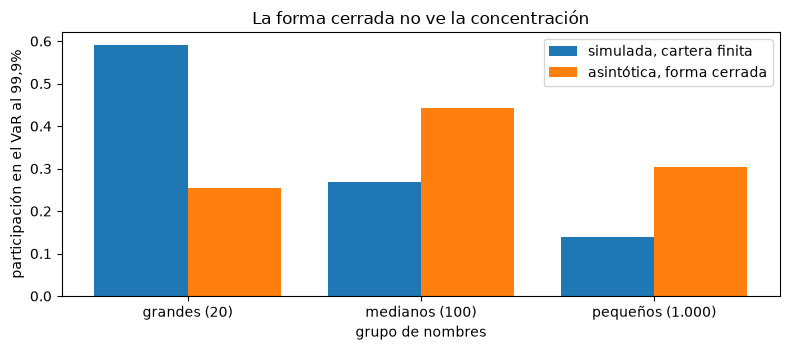

In [7]:
# Dibujar la participación en el VaR simulada y asintótica de cada grupo
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(position - 0.2, shares["VaR"], width=0.4, label="simulada, cartera finita")
ax.bar(position + 0.2, asymptotic_share, width=0.4, label="asintótica, forma cerrada")
ax.set_xticks(position, group_labels)
ax.set_xlabel("grupo de nombres")
ax.set_ylabel("participación en el VaR al 99,9%")
ax.set_title("La forma cerrada no ve la concentración")
ax.legend()
fig.tight_layout()
plt.show()

Las dos barras de cada grupo discrepan en direcciones opuestas para los nombres grandes y medianos: la forma cerrada da a los 20 nombres grandes cerca de un cuarto del capital donde la simulación les da cerca de seis décimos, y da a los medianos mucho más que la simulación. La forma cerrada usa la PD y la exposición propias de cada nombre y supone infinitos otros nombres que la diversifican, así que no puede ver que 20 nombres de 2 millones de USD son grumosos. La simulación lo ve porque sortea cada nombre. La figura compara participaciones del mismo riesgo total en un nivel de confianza, y no dice qué participación es la correcta para un banco, solo que la concentración redistribuye el capital entre los grupos.

### Paso 4: el muestreo por importancia para la cola

Para estimar un cuantil al 99,9% con Monte Carlo simple, solo el 0,1% de los escenarios cae en la cola, y los errores de medias por lotes del notebook 03 fueron grandes. El **muestreo por importancia** sortea los escenarios desde una distribución que visita la cola más seguido y corrige cada uno con una razón de verosimilitud. Para la cópula gaussiana con factores no correlacionados, el giro exponencial de Glasserman y Li (2005, https://doi.org/10.1287/mnsc.1050.0415) funciona en dos partes. Dado el factor sistemático $z$, cada probabilidad de incumplimiento condicional $p_i(z)$ se inclina, con $c_i=\mathrm{EAD}_i\,\mathrm{LGD}_i$ la pérdida del nombre $i$:

$$p_{i,\theta}(z)=\frac{p_i(z)\,e^{\theta c_i}}{1+p_i(z)\,(e^{\theta c_i}-1)},\qquad \theta=\theta(z)\ \text{la raíz de}\ \sum_i c_i\,p_{i,\theta}(z)=x$$

de modo que la pérdida media condicional inclinada es igual al umbral $x$ (y $\theta=0$ donde la media sin inclinar ya lo supera); luego el propio factor se sortea con una media desplazada $\mu$. Cada escenario lleva el peso $w=\exp\!\big(-\theta L+\sum_i\ln(1+p_i(e^{\theta c_i}-1))\big)\exp\!\big(-\mu z+\mu^2/2\big)$ en el caso de un factor, con $E_Q[w]=1$ y $E_Q[wL]=\mathrm{EL}$ para cualquier $\theta(z)\ge0$ y cualquier $\mu$: el estimador es insesgado sea cual sea la inclinación, y solo su varianza depende de ella. Una advertencia de la investigación: el dossier marca su transcripción del giro y del desplazamiento de la media como UNVERIFIED frente al artículo, que es de pago, así que el motor no acepta nada por confianza y su aceptación es la insesgadez comprobada frente al Monte Carlo simple, que repetimos abajo. La celda siguiente toma un escenario, el valor del factor del desplazamiento propio del caso, y muestra el giro en acción: las probabilidades de incumplimiento condicionales antes y después, y la comprobación de que la pérdida media inclinada es igual al objetivo. El objetivo es el VaR al 99,9% de Monte Carlo simple del Paso 1.

In [8]:
# Mostrar el giro exponencial para un valor del factor: probabilidades condicionales de incumplimiento antes y después
from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import importance

threshold = measures[1].var
shift = next(p["value"] for p in rungs["c6-is-gaussian"]["parameters"] if p["name"] == "factor_shift")
loss_of_name = one.ead * one.lgd
p_group = [float(conditional_pd(g["pd"], rho_hat, shift)) for g in groups]
p_cond = np.repeat(p_group, [g["n_names"] for g in groups])
theta = importance.solve_theta(p_cond, loss_of_name, threshold)
p_twist = importance.twisted_pd(p_cond, loss_of_name, theta)

print("pérdida objetivo (VaR de Monte Carlo simple al 99,9%):", f"{threshold:,.0f}")
print("valor del factor:", round(shift, 4), "| theta:", f"{theta:.3e}")
print("pérdida media dado el factor, sin giro:", f"{loss_of_name @ p_cond:,.0f}")
print("pérdida media dado el factor, con giro:", f"{loss_of_name @ p_twist:,.0f}")
for k, g in enumerate(groups):
    print(f"{g['id']:9s} antes: {p_cond[cut[k]]:.4f} | tras el giro: {p_twist[cut[k]]:.4f}")

pérdida objetivo (VaR de Monte Carlo simple al 99,9%): 3,087,000
valor del factor: -2.3235 | theta: 1.822e-06
pérdida media dado el factor, sin giro: 1,479,392
pérdida media dado el factor, con giro: 3,087,000
g-large   antes: 0.0201 | tras el giro: 0.0956
g-mid     antes: 0.0364 | tras el giro: 0.0499
g-small   antes: 0.0513 | tras el giro: 0.0521


La celda siguiente dibuja la probabilidad de incumplimiento condicional de cada grupo antes y después del giro.

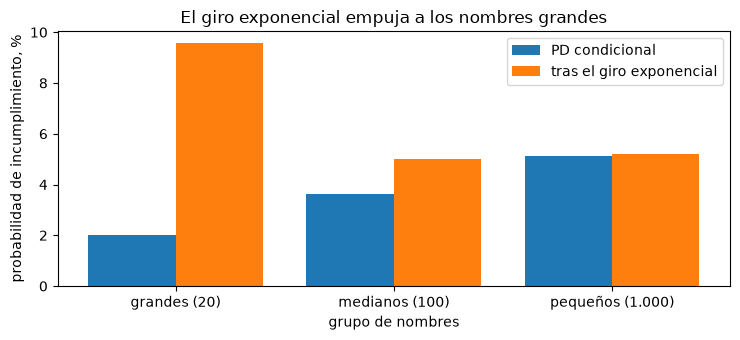

In [9]:
# Dibujar la probabilidad de incumplimiento condicional de cada grupo antes y después del giro
before = np.array([p_cond[cut[k]] for k in range(len(groups))])
after = np.array([p_twist[cut[k]] for k in range(len(groups))])

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.bar(position - 0.2, 100 * before, width=0.4, label="PD condicional")
ax.bar(position + 0.2, 100 * after, width=0.4, label="tras el giro exponencial")
ax.set_xticks(position, group_labels)
ax.set_xlabel("grupo de nombres")
ax.set_ylabel("probabilidad de incumplimiento, %")
ax.set_title("El giro exponencial empuja a los nombres grandes")
ax.legend()
fig.tight_layout()
plt.show()

El giro no es uniforme. Los nombres grandes, que llevan la mayor pérdida por incumplimiento, ven su probabilidad de incumplimiento condicional multiplicada varias veces, los medianos suben moderadamente y los pequeños casi no se mueven. Es la asignación correcta del esfuerzo: para alcanzar una pérdida de 3 millones de USD la simulación necesita incumplimientos entre los nombres grumosos, así que los hace frecuentes y luego corrige con los pesos. Las barras muestran un valor del factor; el estimador aplica la construcción en los valores del factor que sortea. Un giro mal elegido seguiría siendo insesgado, solo más lento, lo que verifica el paso siguiente frente al Monte Carlo simple.

El giro empuja más a los nombres grandes, porque llevan las pérdidas mayores. Ahora el estimador. La celda siguiente sortea 20.000 escenarios de muestreo por importancia con la semilla del caso y el VaR de Monte Carlo simple como objetivo, y comprueba lo que promete la teoría: el desplazamiento del factor que resolvió el motor, la media de los pesos (1 en esperanza) y la pérdida media ponderada (la pérdida esperada en esperanza). Luego lee el VaR y el ES al 99% y al 99,9% con `weighted_var_es`, que normaliza la cola por el número de escenarios y nunca por la suma realizada de los pesos, y los pone junto al Monte Carlo simple de los 100.000 escenarios.

In [10]:
# Sortear 20.000 escenarios de muestreo por importancia, comprobar las identidades de insesgadez y leer VaR y ES
n_is = 20_000
seed_is = rungs["c6-is-gaussian"]["simulation"]["seed"]
result = importance.importance_sample_gaussian(one, threshold, n_is, seed_is, None, sim["chunk_size"])
w = result.weights
print("desplazamiento del factor resuelto por el motor:", round(float(result.factor_shift[0]), 6))
print("media de los pesos (1 en esperanza):", round(float(w.mean()), 4))
print("pérdida media ponderada:", f"{float(np.mean(w * result.losses)):,.0f}", "| EL:", f"{el:,.0f}")
print("parte efectiva de la muestra:", round(float(w.sum() ** 2 / (w.size * np.sum(w * w))), 5))

plain = {m.level: m for m in measures}
is_se = {}
print(f"{'q':>6s} {'VaR IS':>12s} {'error':>9s} {'VaR simple':>16s} {'error':>9s}")
for q in (0.99, 0.999):
    var_i, es_i, se_v, se_e = importance.weighted_var_es(result, q)
    is_se[q] = (se_v, se_e)
    print(f"{q:6.3f} {var_i:12,.0f} {se_v:9,.0f} {plain[q].var:16,.0f} {plain[q].var_se:9,.0f}")
    print(f"       ES IS {es_i:12,.0f} {se_e:9,.0f} | ES simple: {plain[q].es:12,.0f} {plain[q].es_se:9,.0f}")

desplazamiento del factor resuelto por el motor: -2.271303
media de los pesos (1 en esperanza): 0.5522
pérdida media ponderada: 335,666 | EL: 409,721
parte efectiva de la muestra: 0.0024
     q       VaR IS     error       VaR simple     error
 0.990    2,106,000     7,788        2,088,000    18,433
       ES IS    2,577,016     3,389 | ES simple:    2,535,057    24,792
 0.999    3,204,000     6,953        3,087,000    54,340
       ES IS    3,701,551     5,585 | ES simple:    3,609,180    87,336


La razón de varianza es el número de escenarios de Monte Carlo simple que vale un escenario de muestreo por importancia. `variance_ratio` del motor es $(\mathrm{ee}_{\text{simple}}/\mathrm{ee}_{\text{IS}})^2$ con igual tamaño de muestra, así que el error simple de 100.000 escenarios se escala primero a 20.000 por $\sqrt{100.000/20.000}$. La celda siguiente la calcula para el VaR y el ES al 99,9% y dibuja los errores estándar de ambos estimadores con 20.000 escenarios.

razón de varianza, VaR 99,9%: 305
razón de varianza, ES 99,9%: 1223
cada escenario de muestreo por importancia vale cerca de 305 escenarios simples para el VaR


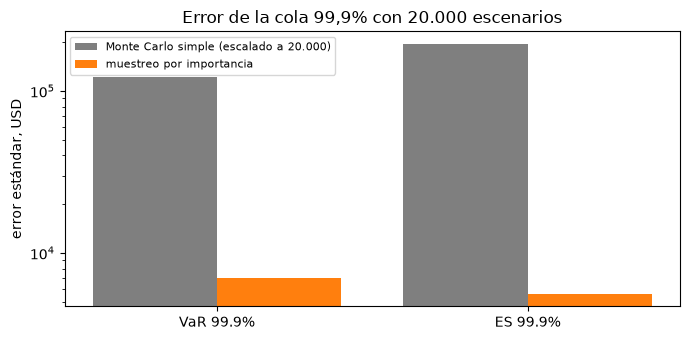

In [11]:
# Calcular la razón de varianza frente al Monte Carlo simple con igual tamaño de muestra y dibujar los dos errores
scale = math.sqrt(100_000 / n_is)
plain_se = (plain[0.999].var_se * scale, plain[0.999].es_se * scale)
ratio_var = importance.variance_ratio(plain_se[0], is_se[0.999][0])
ratio_es = importance.variance_ratio(plain_se[1], is_se[0.999][1])
print("razón de varianza, VaR 99,9%:", round(ratio_var))
print("razón de varianza, ES 99,9%:", round(ratio_es))
print("cada escenario de muestreo por importancia vale cerca de", round(ratio_var), "escenarios simples para el VaR")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(np.arange(2) - 0.2, plain_se, width=0.4, color="tab:gray", label="Monte Carlo simple (escalado a 20.000)")
ax.bar(np.arange(2) + 0.2, is_se[0.999], width=0.4, color="tab:orange", label="muestreo por importancia")
ax.set_xticks(range(2), ["VaR 99.9%", "ES 99.9%"])
ax.set_yscale("log")
ax.set_ylabel("error estándar, USD")
ax.set_title("Error de la cola 99,9% con 20.000 escenarios")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las barras naranjas están de uno a dos órdenes de magnitud bajo las grises en un eje logarítmico, tanto para el VaR como para el déficit esperado. Con igual tamaño de muestra el estimador de muestreo por importancia es entonces muchas veces más preciso, y la razón de varianza impresa arriba lo traduce en el número de escenarios simples que vale cada uno de los suyos. La ganancia es mayor donde la cola es más rara, que es el nivel de 99,9% que usa el capital. La figura compara errores que son a su vez estimaciones por lotes, así que las razones son órdenes de magnitud y no constantes exactas, y otra semilla las movería. El motor no tiene giro para la cópula t de Student, así que esta ganancia no se traslada a ese modelo.

## Resultados

**Respuesta:** los 20 nombres grandes son dueños del 59,1% del valor en riesgo al 99,9% de 3.087.000 USD siendo el 40% de la exposición, y el muestreo por importancia alcanza esa cola con un error estándar de 6.953 USD con 20.000 escenarios, donde el Monte Carlo simple con 100.000 escenarios tiene 54.340 USD: cada escenario de muestreo por importancia vale cerca de 305 simples para el VaR.

- **Las contribuciones suman, exactamente para el ES y dentro de una tolerancia para el VaR.** Las contribuciones al ES de los tres grupos suman el ES muestral con una brecha relativa de 1,3e-15 al 99% y 1,3e-16 al 99,9%, ambas verdes: los pesos de Acerbi y Tasche hacen que la suma sea una identidad. Las contribuciones al VaR por núcleo suman 2.087.480 frente a un VaR de 2.088.000 al 99% (brecha 2,5e-4) y 3.082.159 frente a 3.087.000 al 99,9% (brecha 1,6e-3), ambas dentro de la tolerancia de 0,01 y verdes. Una brecha bajo la tolerancia no es cero, y la prueba es una puerta de Contraste, no un umbral regulatorio.
- **Los nombres grandes llevan mucho más capital que su exposición.** Los 20 nombres grandes son el 40% de la exposición y llevan el 59,1% del VaR al 99,9% y el 57,6% del ES. Los nombres medianos son el 40% de la exposición y llevan el 26,9% del VaR, los 1.000 nombres pequeños el 20% de la exposición y el 13,9%.
- **Las contribuciones al VaR son más ruidosas que las del ES, aunque con 50.000 escenarios no por mucho.** En seis semillas el coeficiente de variación de la participación al 99,9% de los nombres grandes es 4,1% para la contribución al ES, 5,4% para la contribución al VaR por núcleo y 6,1% para la estimación simple desde los escenarios cercanos al VaR, y el mismo orden vale para los nombres medianos y pequeños (5,7%, 8,2%, 8,8% y 4,7%, 6,7%, 7,6%). El núcleo suaviza la estimación simple, y la contribución al ES es más estable que ambas.
- **Las contribuciones asintóticas no ven la concentración.** Las contribuciones ASRF de forma cerrada suman 2.259.748 USD al 99,9% y dan a los nombres grandes el 25,5% del capital frente al 59,1% simulado, y a los medianos el 44,2% frente al 26,9%. Dependen de cada nombre solo por su propia PD y exposición, así que son invariantes a la cartera: un nombre de 2 millones de USD recibe el mismo capital por dólar en una cartera de 1.120 nombres y en una de 20. La cartera finita concentra el capital en sus nombres mayores, y una forma cerrada que ignora el resto de la cartera no lo ve.
- **La concentración en un número.** El índice de Herfindahl es 0,00964 y el número efectivo de nombres 103,73 de los 1.120; el mismo total repartido en exposiciones iguales sería 0,000893 y 1.120 nombres efectivos. El mayor nombre es el 2% de la exposición.
- **El giro exponencial mueve la pérdida adonde está la cola.** Para el valor del factor -2,3235 la pérdida media dado el factor es 1.479.392 USD sin giro y, tras resolver theta (1,822e-6), 3.087.000 USD, el objetivo. El giro sube la probabilidad de incumplimiento condicional de los nombres grandes de 2,01% a 9,56%, la de los medianos de 3,64% a 4,99% y la de los pequeños de 5,13% a 5,21%: empuja donde la pérdida por nombre es mayor.
- **El estimador es insesgado en esperanza, y la muestra muestra lo que eso significa.** Con 20.000 escenarios los pesos promedian 0,5522, no 1, y la pérdida media ponderada es 335.666 USD frente a la pérdida esperada de 409.721 USD: los pesos tienen cola pesada y una muestra de 20.000 está lejos de su media (la parte efectiva de la muestra es 0,24%). Por eso `weighted_var_es` normaliza la cola por el número de escenarios y nunca por la suma realizada de los pesos. El VaR al 99,9% es 3.204.000 USD con un error estándar de 6.953, que está 117.000 USD sobre los 3.087.000 ± 54.340 de la corrida simple, cerca de dos errores estándar simples. El ES es 3.701.551 ± 5.585 frente a 3.609.180 ± 87.336. La prueba del giro es este acuerdo, porque el dossier marca la transcripción del giro como no verificada frente al artículo.
- **La ganancia es grande.** Con igual tamaño de muestra cada escenario de muestreo por importancia vale cerca de 305 escenarios simples para el VaR al 99,9% y cerca de 1.223 para el ES. Las razones se mueven de una corrida a otra porque ambos errores son estimaciones por lotes y los errores de cola son a su vez ruidosos.

Lo que este notebook no muestra: el muestreo por importancia con t de Student (el motor no tiene giro para ella), el giro multifactorial (el motor solo admite factores no correlacionados), ni las contribuciones de nombres individuales en vez de grupos.

## Resumen

- Las contribuciones de Euler reparten el capital entre grupos y suman el total: exactamente para el déficit esperado (`es_contributions`), dentro de una tolerancia declarada para el VaR (`var_contributions_kernel`), comprobado por `euler_additivity`.
- Las contribuciones al VaR son las más ruidosas de las dos; el núcleo las suaviza pero siguen más ruidosas que las del ES.
- Las contribuciones asintóticas (`asrf_var_contributions`) son invariantes a la cartera y no ven la concentración: los nombres grandes llevan mucho más capital en la cartera finita que el que les da la forma cerrada. `hhi` y `effective_names` miden la concentración.
- El muestreo por importancia con el giro exponencial (`solve_theta`, `twisted_pd`, `importance_sample_gaussian`, `weighted_var_es`) alcanza la cola al 99,9% con cientos de veces menos varianza, y su insesgadez es la prueba de aceptación mientras la transcripción del giro no esté verificada.

**Qué probar a continuación.** Cambia las semillas del Paso 2 y mira cómo se mantiene el orden de los tres estimadores. Luego abre el notebook 06, donde las pruebas de esta batería se leen juntas en los cinco tipos de préstamo.

## Referencias

- Tasche, D. (2008), Capital allocation to business units and sub-portfolios: the Euler principle, arXiv 0708.2542. https://arxiv.org/abs/0708.2542
- Tasche, D. (2009), Capital allocation for credit portfolios with kernel estimators, Quantitative Finance 9(5):581-595. https://doi.org/10.1080/14697680802620599
- Emmer, S. y Tasche, D. (2005), Calculating credit risk capital charges with the one-factor model, Journal of Risk 7(2):85-101, arXiv cond-mat/0302402. https://arxiv.org/abs/cond-mat/0302402
- Glasserman, P. y Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Acerbi, C. y Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Federal Reserve charge-off table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm (public domain; licence class mirror-allowed).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.2, H.6 and H.7 (Euler contributions, concentration and rare-event simulation; the transcription of the twist is marked UNVERIFIED there).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.